# Poster figures

All figures for the poster, in one consistent style. Nothing is retrained here: the numbers come from `results/poster/*.csv`, which `scripts/collect_poster_results.py` copies from the executed notebooks (06, 08, 09, 10). The cluster figures are in notebook 11.

Figures are saved to `figures/` as PNG (300 dpi) and PDF.

Style:
- each model keeps the same colour in every figure (VaDeSC blue, Cox orange, RSF green, DSM yellow, Weibull AFT pink), with a different marker shape as a second cue,
- C-index is shown as dots with ±1 std error bars (no bars, since the C-index scale doesn't start at 0),
- the number of runs is in each caption.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

R = Path("../results/poster")
OUT = Path("../figures")
OUT.mkdir(exist_ok=True)

INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3de"
COLORS = {"VaDeSC": "#2a78d6", "Cox PH": "#eb6834", "RSF": "#1baf7a", "DSM": "#eda100", "Weibull AFT": "#e87ba4"}
MARKERS = {"VaDeSC": "o", "Cox PH": "s", "RSF": "^", "DSM": "D", "Weibull AFT": "v"}
GRAY = "#a3a29b"

plt.rcParams.update({
    "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": INK, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "x",
    "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 9, "figure.dpi": 110, "savefig.bbox": "tight",
})

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}", dpi=300)
    plt.show()

def dots(ax, labels, means, stds, colors, markers):
    y = np.arange(len(labels))[::-1]
    for yi, m, s, c, mk in zip(y, means, stds, colors, markers):
        ax.errorbar(m, yi, xerr=s, fmt=mk, color=c, ecolor=c, elinewidth=2, capsize=0, markersize=10,
                    markeredgecolor="white", markeredgewidth=1.5)
        ax.annotate(f"{m:.3f}", (m, yi), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=11, color=INK)
    ax.set_yticks(y, labels)
    ax.set_ylim(-0.7, len(labels) - 0.3)
    ax.grid(False, axis="y")

def model_legend(fig, models, spread, extra=(), ncol=None):
    # legend below the figure: one marker per model, plus what the error bars mean
    h = [Line2D([], [], marker=MARKERS[m], ls="", color=COLORS[m], markersize=10, markeredgecolor="white", label=m) for m in models]
    h += list(extra) + [Line2D([], [], color=GRAY, lw=2, label=spread)]
    fig.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=ncol or len(h), fontsize=11)

## 1. Simulated data: prediction and clustering

Simulated data from the official VaDeSC generator (10,000 patients, 1,000 features, 3 true clusters), 5 seeds. IBS for every model is averaged over seeds 0, 1, 2, 4 (seed 3 has no saved IBS).

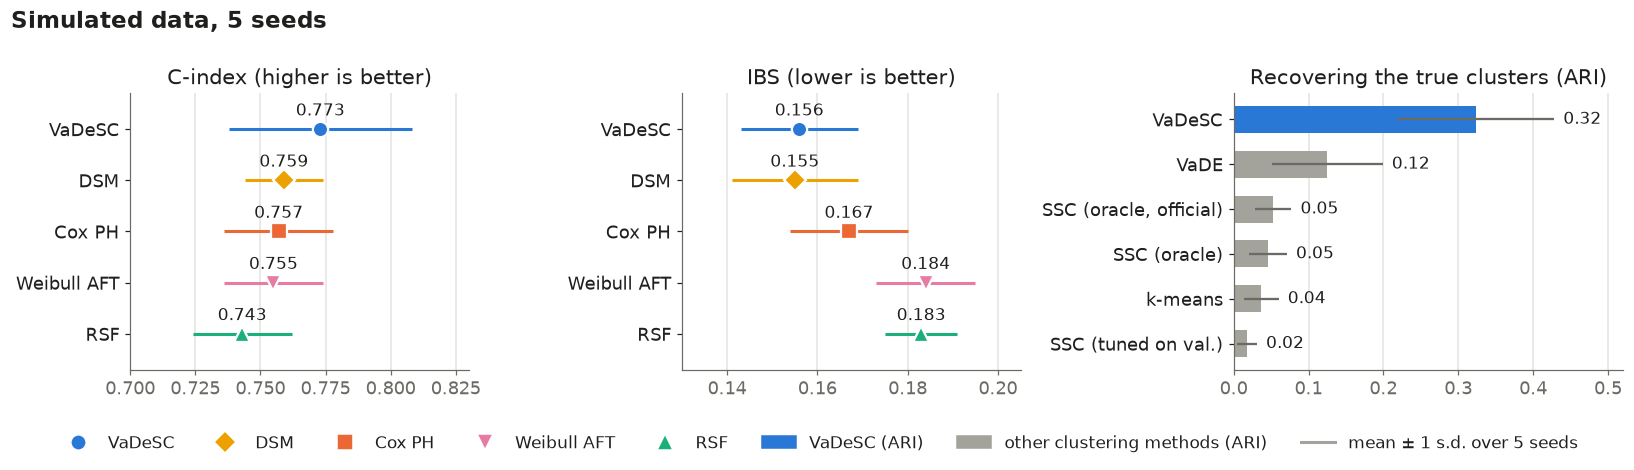

In [2]:
pred = pd.read_csv(R / "sim_prediction.csv").set_index("model").reindex(["VaDeSC", "DSM", "Cox PH", "Weibull AFT", "RSF"])
clus = pd.read_csv(R / "sim_clustering.csv").set_index("model")
clus = clus.reindex(["VaDeSC", "VaDE", "SSC (oracle, official ranking)", "SSC (oracle)", "k-means (all features)", "SSC (val log-rank)"])
nice = {"SSC (oracle, official ranking)": "SSC (oracle, official)", "k-means (all features)": "k-means", "SSC (val log-rank)": "SSC (tuned on val.)"}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.15]})
m = list(pred.index)
dots(ax[0], m, pred["C-index | mean"], pred["C-index | std"], [COLORS[k] for k in m], [MARKERS[k] for k in m])
ax[0].set(title="C-index (higher is better)", xlim=(0.70, 0.83))
dots(ax[1], m, pred["IBS | mean"], pred["IBS | std"], [COLORS[k] for k in m], [MARKERS[k] for k in m])
ax[1].set(title="IBS (lower is better)", xlim=(0.13, 0.205))

y = np.arange(len(clus))[::-1]
c = [COLORS["VaDeSC"] if k == "VaDeSC" else GRAY for k in clus.index]
ax[2].barh(y, clus["ARI | mean"], xerr=clus["ARI | std"], color=c, height=0.6, error_kw={"ecolor": MUTED, "elinewidth": 1.5})
for yi, v, sd in zip(y, clus["ARI | mean"], clus["ARI | std"]):
    ax[2].annotate(f"{v:.2f}", (v + sd, yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=11)
ax[2].set_yticks(y, [nice.get(k, k) for k in clus.index]); ax[2].grid(False, axis="y")
ax[2].set(title="Recovering the true clusters (ARI)", xlim=(0, 0.52))
fig.suptitle("Simulated data, 5 seeds", x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout()
from matplotlib.patches import Patch
model_legend(fig, m, "mean ± 1 s.d. over 5 seeds",
             extra=[Patch(color=COLORS["VaDeSC"], label="VaDeSC (ARI)"), Patch(color=GRAY, label="other clustering methods (ARI)")])
save(fig, "sim_benchmark")

## 2. Real datasets: prediction

3 seeds (different data split and initialisation). SUPPORT uses only variables known at study entry. WHAS500 without `los`.

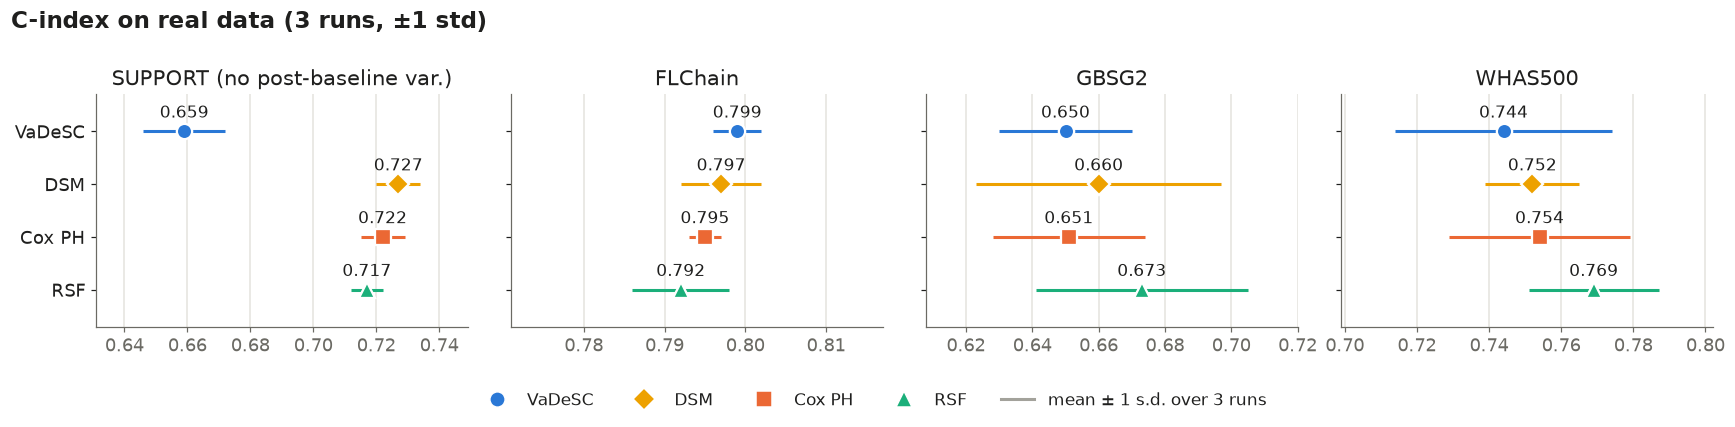

In [3]:
real = pd.read_csv(R / "real_prediction.csv")
datasets = ["SUPPORT (baseline-only)", "FLChain", "GBSG2", "WHAS500"]
models = ["VaDeSC", "DSM", "Cox PH", "RSF"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, ds in zip(axes, datasets):
    t = real[real.dataset == ds].set_index("model").reindex(models)
    dots(ax, models, t["C-index | mean"], t["C-index | std"], [COLORS[k] for k in models], [MARKERS[k] for k in models])
    lo, hi = (t["C-index | mean"] - t["C-index | std"]).min(), (t["C-index | mean"] + t["C-index | std"]).max()
    pad = max(0.015, (hi - lo) * 0.15)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_title(ds.replace(" (baseline-only)", " (no post-baseline var.)"))
axes[0].set_ylabel("")
fig.suptitle("C-index on real data (3 runs, ±1 std)", x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout(); model_legend(fig, models, "mean ± 1 s.d. over 3 runs"); save(fig, "real_prediction")

## 3. Feature leakage in SUPPORT

The paper's preprocessing keeps 4 variables recorded after study entry (`sfdm2`, `slos`, `charges`, `totcst`). Without them every model drops, VaDeSC the most. From notebook 10 (3 splits; VaDeSC 3 splits × 3 seeds).

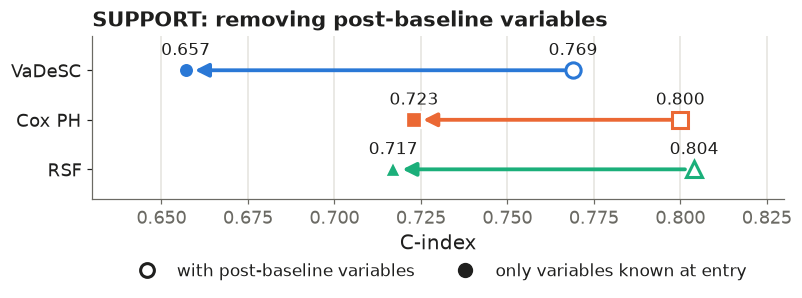

In [4]:
leak = pd.read_csv(R / "leakage.csv").set_index("model").reindex(["VaDeSC", "Cox PH", "RSF"])
w, wo = "mean | with post-baseline variables", "mean | without post-baseline variables"
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(leak))[::-1]
for yi, (k, r) in zip(y, leak.iterrows()):
    ax.annotate("", xy=(r[wo], yi), xytext=(r[w], yi),
                arrowprops=dict(arrowstyle="-|>", color=COLORS[k], lw=2.5, mutation_scale=18, shrinkA=6, shrinkB=6))
    ax.plot(r[w], yi, MARKERS[k], color="white", markeredgecolor=COLORS[k], markeredgewidth=2, markersize=10)
    ax.plot(r[wo], yi, MARKERS[k], color=COLORS[k], markeredgecolor="white", markeredgewidth=1.5, markersize=10)
    ax.annotate(f"{r[w]:.3f}", (r[w], yi), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=11)
    ax.annotate(f"{r[wo]:.3f}", (r[wo], yi), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=11)
ax.set_yticks(y, leak.index); ax.grid(False, axis="y"); ax.set_ylim(-0.6, len(leak) - 0.3)
ax.set(xlabel="C-index", xlim=(0.63, 0.83))
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="white", markeredgecolor=INK, markeredgewidth=2, label="with post-baseline variables"),
                   Line2D([], [], marker="o", ls="", color=INK, label="only variables known at entry")],
          loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=11)
ax.set_title("SUPPORT: removing post-baseline variables", loc="left", fontweight="bold")
plt.tight_layout(); save(fig, "leakage")

## 4. Missingness in SUPPORT is related to the outcome

Baseline-only features with at least 1% missing values. Patients with a missing value died more often for most features.

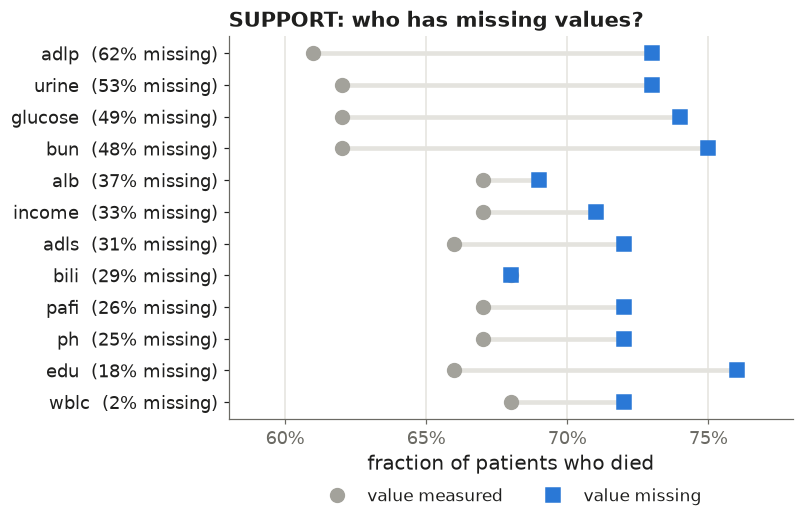

In [5]:
sm = pd.read_csv(R / "support_missingness.csv").sort_values("missing")
fig, ax = plt.subplots(figsize=(7.5, 5))
y = np.arange(len(sm))
ax.hlines(y, sm["death rate if measured"], sm["death rate if missing"], color=GRID, lw=3)
ax.plot(sm["death rate if measured"], y, "o", color=GRAY, markersize=9, label="value measured")
ax.plot(sm["death rate if missing"], y, "s", color=COLORS["VaDeSC"], markersize=9, label="value missing")
ax.set_yticks(y, [f"{f}  ({m:.0%} missing)" for f, m in zip(sm.feature, sm.missing)])
ax.grid(False, axis="y")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(xlabel="fraction of patients who died", xlim=(0.58, 0.78))
ax.set_xticks([0.60, 0.65, 0.70, 0.75])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=11)
ax.set_title("SUPPORT: who has missing values?", loc="left", fontweight="bold")
plt.tight_layout(); save(fig, "support_missingness")

## 5. Does the missingness mask help?

Same encoding in all three figures: colour = model family (Cox orange, VaDeSC blue), marker = how missing values are handled.
- mean imputation (circle), mask as extra input (square), MissVaDeSC: mask as input, reconstruct only observed values (triangle), MissVaDeSC + a decoder for the mask (diamond).

Simulated data: 6,000 patients, 30 features, 3 clusters, 30% missing, 5 seeds. SUPPORT: 3 seeds.

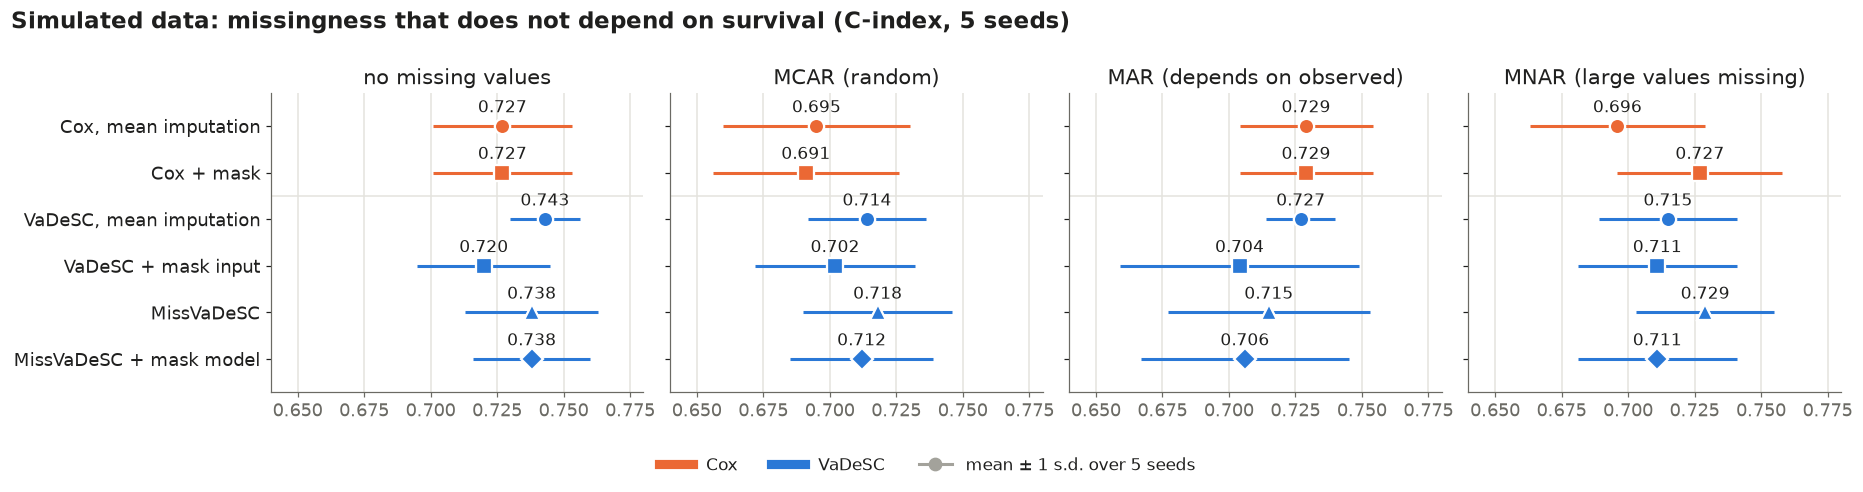

In [6]:
METHODS = ["Cox (mean imp.)", "Cox (+mask)", "VaDeSC (mean imp.)", "VaDeSC (+mask input)", "MissVaDeSC", "MissVaDeSC + mask model"]
LABEL = {"Cox (mean imp.)": "Cox, mean imputation", "Cox (+mask)": "Cox + mask",
         "VaDeSC (mean imp.)": "VaDeSC, mean imputation", "VaDeSC (+mask input)": "VaDeSC + mask input",
         "MissVaDeSC": "MissVaDeSC", "MissVaDeSC + mask model": "MissVaDeSC + mask model"}
MCOL = {m: COLORS["Cox PH"] if m.startswith("Cox") else COLORS["VaDeSC"] for m in METHODS}
MMK = dict(zip(METHODS, ["o", "s", "o", "s", "^", "D"]))

def method_panel(ax, t, title, show_labels):
    t = t.set_index("method").reindex(METHODS)
    dots(ax, [LABEL[m] for m in METHODS], t["C-index | mean"], t["C-index | std"], [MCOL[m] for m in METHODS], [MMK[m] for m in METHODS])
    ax.axhline(3.5, color=GRID, lw=1)  # separates Cox from VaDeSC variants
    ax.set_title(title)
    if not show_labels:
        ax.tick_params(labelleft=False)

def method_legend(fig, spread="mean ± 1 s.d. over 5 seeds"):
    # the rows name the methods, so the legend only explains the colours and the bars
    h = [Line2D([], [], color=COLORS["Cox PH"], lw=6, label="Cox"),
         Line2D([], [], color=COLORS["VaDeSC"], lw=6, label="VaDeSC"),
         Line2D([], [], color=GRAY, lw=2, marker="o", markersize=8, label=spread)]
    fig.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=11)

mech = pd.read_csv(R / "missingness_mechanisms.csv")
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, (mk, title) in zip(axes, [("none", "no missing values"), ("MCAR", "MCAR (random)"),
                                   ("MAR", "MAR (depends on observed)"), ("MNAR", "MNAR (large values missing)")]):
    method_panel(ax, mech[mech.mechanism == mk], title, ax is axes[0])
    ax.set_xlim(0.64, 0.78)
fig.suptitle("Simulated data: missingness that does not depend on survival (C-index, 5 seeds)", x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout(); method_legend(fig); save(fig, "missingness_mechanisms")

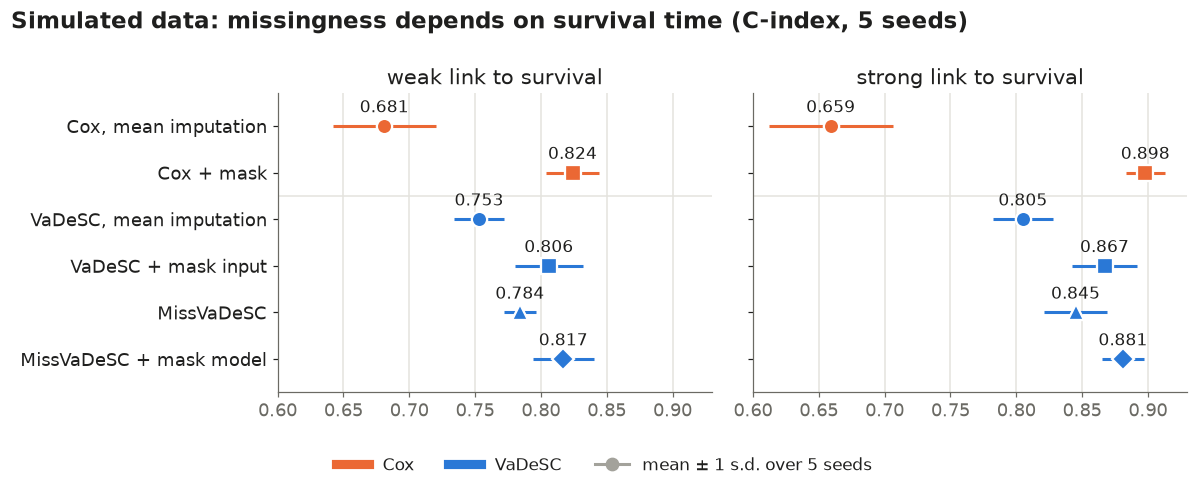

In [7]:
sv = pd.read_csv(R / "missingness_survival.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (s, title) in zip(axes, [(1.0, "weak"), (3.0, "strong")]):
    method_panel(ax, sv[sv.strength == s], f"{title} link to survival", ax is axes[0])
    ax.set_xlim(0.6, 0.93)
fig.suptitle("Simulated data: missingness depends on survival time (C-index, 5 seeds)", x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout(); method_legend(fig); save(fig, "missingness_survival")

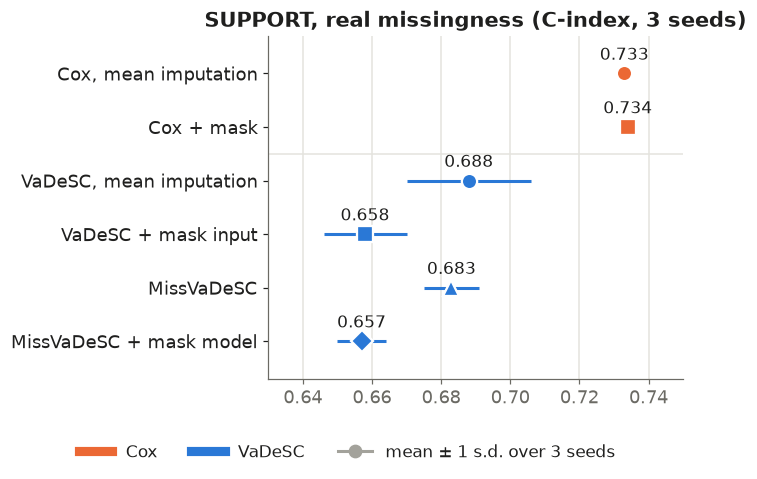

In [8]:
sup = pd.read_csv(R / "missingness_support.csv")
fig, ax = plt.subplots(figsize=(6.5, 4))
method_panel(ax, sup, "SUPPORT, real missingness (C-index, 3 seeds)", True)
ax.set_xlim(0.63, 0.75)
ax.title.set_fontweight("bold")
plt.tight_layout(); method_legend(fig, spread="mean ± 1 s.d. over 3 seeds"); save(fig, "missingness_support")

## 6. VAE imputation vs median imputation (SUPPORT)

From notebook 10: 3 data splits; VaDeSC 3 splits × 5 seeds.

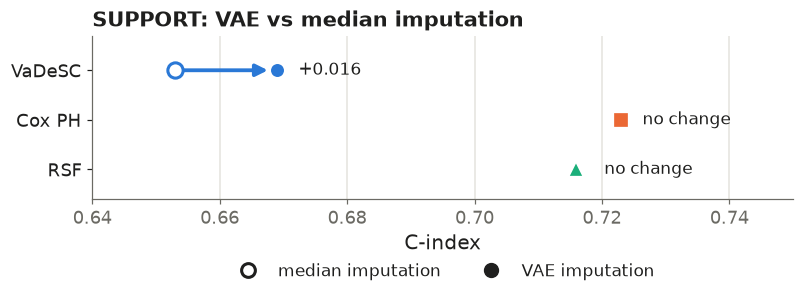

In [9]:
imp = pd.read_csv(R / "imputation.csv")
models = ["VaDeSC", "Cox PH", "RSF"]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(models))[::-1]
for yi, k in zip(y, models):
    t = imp[imp.model == k].set_index("data")["C-index | mean"]
    a, b = t["median imputation"], t["VAE imputation"]
    if abs(b - a) >= 0.003:
        ax.annotate("", xy=(b, yi), xytext=(a, yi),
                    arrowprops=dict(arrowstyle="-|>", color=COLORS[k], lw=2.5, mutation_scale=16, shrinkA=6, shrinkB=6))
        ax.plot(a, yi, MARKERS[k], color="white", markeredgecolor=COLORS[k], markeredgewidth=2, markersize=10)
        txt = f"{b - a:+.3f}"
    else:
        txt = "no change"
    ax.plot(b, yi, MARKERS[k], color=COLORS[k], markeredgecolor="white", markeredgewidth=1.5, markersize=10)
    ax.annotate(txt, (max(a, b), yi), xytext=(14, 0), textcoords="offset points", va="center", fontsize=11)
ax.set_yticks(y, models); ax.grid(False, axis="y"); ax.set_ylim(-0.6, len(models) - 0.3)
ax.set(xlabel="C-index", xlim=(0.64, 0.75))
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="white", markeredgecolor=INK, markeredgewidth=2, label="median imputation"),
                   Line2D([], [], marker="o", ls="", color=INK, label="VAE imputation")],
          loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=11)
ax.set_title("SUPPORT: VAE vs median imputation", loc="left", fontweight="bold")
plt.tight_layout(); save(fig, "imputation")

## 7. VaDeSC clusters on SUPPORT (baseline-only, seed 0)

From notebook 11. Clusters are numbered by 1-year mortality (C1 highest). Left: Kaplan-Meier curves. Right: how each cluster differs from all patients, in standard deviations (blue = higher than average, orange = lower), with the cluster's median or percentage written in each cell.

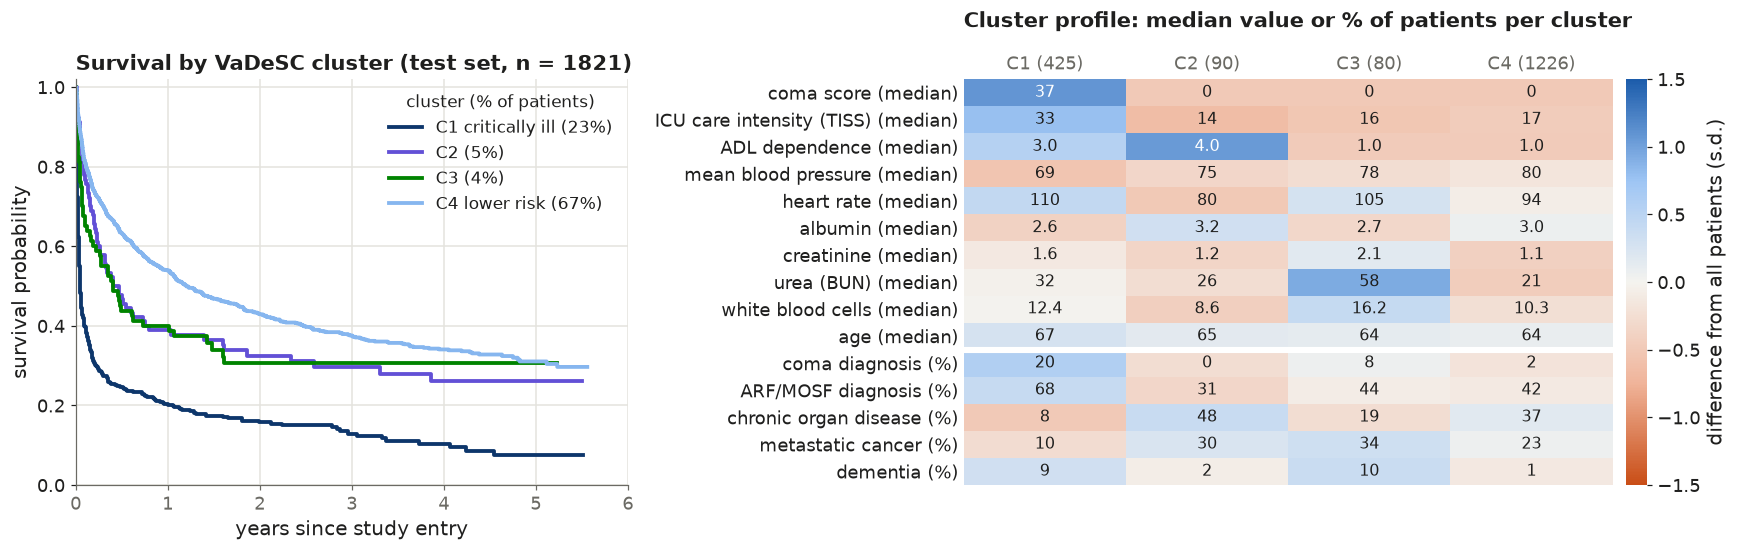

In [10]:
from lifelines import KaplanMeierFitter

cl = pd.read_csv(R / "support_clusters.csv")
clusters = sorted(cl.cluster.unique())
RAMP = ["#0d366b", "#6250d6", "#008300", "#86b6ef"]  # C1 / C4 (stable) in dark / light blue, small clusters C2, C3 in their own hues
NAMES = {"C1": "critically ill", "C4": "lower risk"}

fig, (ax, hx) = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})
for c, col in zip(clusters, RAMP):
    g = cl[cl.cluster == c]
    km = KaplanMeierFitter().fit(g["d.time"] / 365, g["death"])
    sf = km.survival_function_.iloc[:, 0]
    ax.step(sf.index, sf.values, where="post", color=col, lw=2.5,
            label=f"{c} {NAMES.get(c, '')} ({len(g) / len(cl):.0%})".replace("  ", " "))
ax.set(xlabel="years since study entry", ylabel="survival probability", xlim=(0, 6), ylim=(0, 1.02))
ax.legend(title="cluster (% of patients)", loc="upper right", fontsize=11, title_fontsize=11)
ax.grid(True, axis="y")
ax.set_title("Survival by VaDeSC cluster (test set, n = %d)" % len(cl), loc="left", fontweight="bold")

feat = {"coma score": cl["scoma"], "ICU care intensity (TISS)": cl["avtisst"], "ADL dependence": cl["adlsc"],
        "mean blood pressure": cl["meanbp"], "heart rate": cl["hrt"], "albumin": cl["alb"],
        "creatinine": cl["crea"], "urea (BUN)": cl["bun"], "white blood cells": cl["wblc"], "age": cl["age"],
        "coma diagnosis (%)": 100 * (cl["dzclass"] == "Coma"), "ARF/MOSF diagnosis (%)": 100 * (cl["dzclass"] == "ARF/MOSF"),
        "chronic organ disease (%)": 100 * (cl["dzclass"] == "COPD/CHF/Cirrhosis"),
        "metastatic cancer (%)": 100 * (cl["ca"] == "metastatic"), "dementia (%)": 100 * (cl["dementia"] == 1)}
F = pd.DataFrame(feat)
is_pct = [k.endswith("(%)") for k in F.columns]
val = pd.DataFrame({c: [F[k][cl.cluster == c].mean() if p else F[k][cl.cluster == c].median() for k, p in zip(F.columns, is_pct)]
                    for c in clusters}, index=F.columns)
z = val.sub(F.mean().values, axis=0).div(F.std().values, axis=0)
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap = LinearSegmentedColormap.from_list("div", ["#c94e17", "#f0b49a", "#f4f3ef", "#9ec5f4", "#1c5cab"])
im = hx.imshow(z.values, cmap=cmap, norm=TwoSlopeNorm(0, -1.5, 1.5), aspect="auto")
cb = fig.colorbar(im, ax=hx, fraction=0.04, pad=0.02)
cb.set_label("difference from all patients (s.d.)"); cb.outline.set_visible(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        v = val.iloc[i, j]
        whole = is_pct[i] or val.iloc[i].abs().max() >= 20
        hx.text(j, i, f"{v:.0f}" if whole else f"{v:.1f}", ha="center", va="center", fontsize=10.5,
                color="white" if abs(z.iloc[i, j]) > 1.0 else INK)
hx.set_xticks(range(len(clusters)), [f"{c} ({(cl.cluster == c).sum()})" for c in clusters])
# every row says whether the cells are medians or percentages; a white line separates the two groups
hx.set_yticks(range(len(F.columns)), [k if p else f"{k} (median)" for k, p in zip(F.columns, is_pct)])
hx.axhline(is_pct.index(True) - 0.5, color="white", lw=4)
hx.tick_params(length=0); hx.grid(False)
for sp in hx.spines.values(): sp.set_visible(False)
hx.xaxis.tick_top()
hx.set_title("Cluster profile: median value or % of patients per cluster", loc="left", fontweight="bold", pad=34)
plt.tight_layout(); save(fig, "support_clusters")

## 8. Latent space (SUPPORT, seed 0)

From notebook 11: the test patients in 2D. Left: PCA of the input features. Middle and right: PCA of VaDeSC's 16-dimensional latent embedding, coloured by cluster and by 1-year outcome.

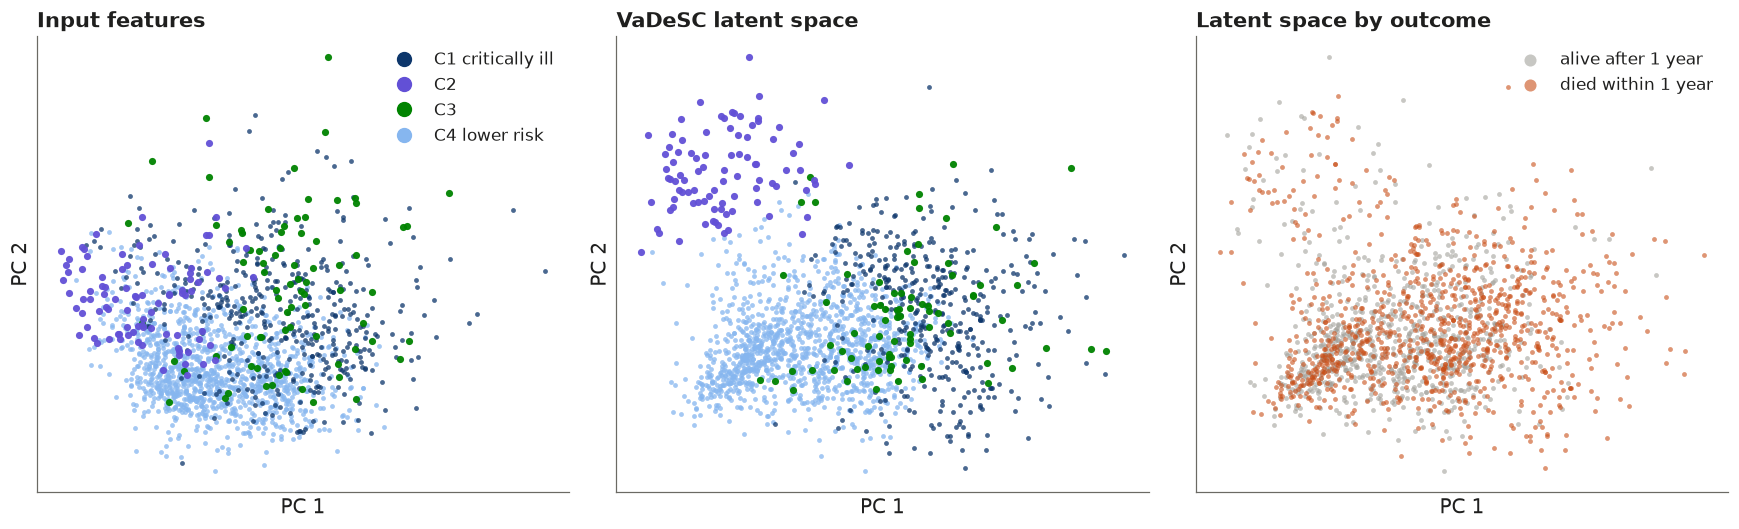

In [11]:
lat = pd.read_csv(R / "support_latent.csv")
CL = dict(zip(clusters, RAMP))
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, (xc, yc, title) in zip(ax[:2], [("input PC1", "input PC2", "Input features"), ("latent PC1", "latent PC2", "VaDeSC latent space")]):
    for c in ["C4", "C1", "C3", "C2"]:  # large clusters first, small ones on top
        m = lat.cluster == c
        a.scatter(lat.loc[m, xc], lat.loc[m, yc], s=10 if c in ("C1", "C4") else 22, color=CL[c], alpha=0.75 if c in ("C1", "C4") else 0.95,
                  linewidths=0,
                  label=f"{c} {NAMES.get(c, '')}".strip())
    a.set_title(title, loc="left", fontweight="bold")
for flag, col, lab in [(False, GRAY, "alive after 1 year"), (True, "#c94e17", "died within 1 year")]:
    m = lat["died within 1 year"] == flag
    ax[2].scatter(lat.loc[m, "latent PC1"], lat.loc[m, "latent PC2"], s=10, color=col, alpha=0.6, linewidths=0, label=lab)
ax[2].set_title("Latent space by outcome", loc="left", fontweight="bold")
for a in ax:
    a.grid(False); a.set_xticks([]); a.set_yticks([])
    a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
ax[0].legend(handles=[Line2D([], [], marker="o", ls="", color=CL[c], markersize=9, label=f"{c} {NAMES.get(c, '')}".strip()) for c in clusters],
             loc="best", fontsize=11)
ax[2].legend(markerscale=2.5, loc="best", fontsize=11)
plt.tight_layout(); save(fig, "support_latent")

## 9. Report figures from the 10-split runs (notebooks 16 and 17)

These read the CSVs of notebooks 16 and 17 directly (`results/support10_*.csv`, `results/real10.csv`). Every point is the mean over the 10 data splits of the per-split value (VaDeSC: mean over seeds within a split), error bars are ±1 s.d. over the splits.

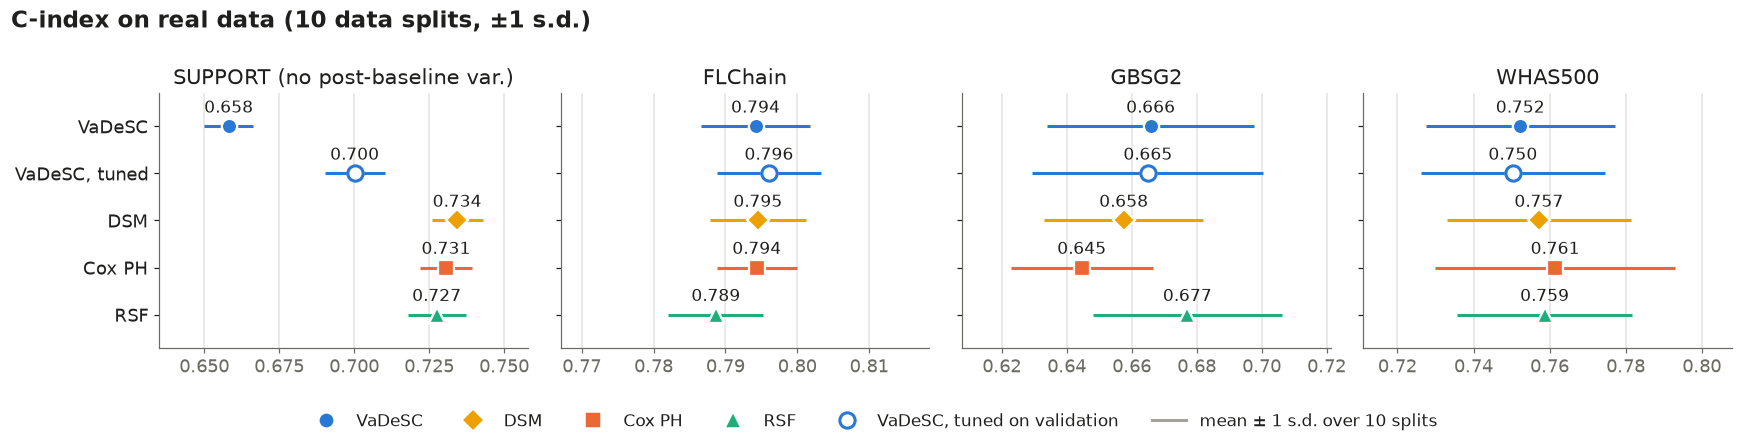

In [12]:
R10 = Path("../results")
def per_split(df, method):
    return df[df.method == method].groupby("split")["C-index"].mean()

sup_cls = pd.read_csv(R10 / "support10_classical.csv")
sup_miss = pd.read_csv(R10 / "support10_missingness.csv")
sup_tune = pd.read_csv(R10 / "support10_tuning.csv")
real10 = pd.read_csv(R10 / "real10.csv")
real10 = real10[real10.stage.isna()]

# per-split C-index for each dataset and model
P = {}
for m in ["Cox PH", "RSF", "DSM"]:
    P[("SUPPORT", m)] = per_split(sup_cls, m)
P[("SUPPORT", "VaDeSC")] = per_split(sup_miss, "VaDeSC, median/mode")
P[("SUPPORT", "VaDeSC, tuned")] = per_split(sup_tune[sup_tune.stage == "test"], "VaDeSC, tuned")
for ds in ["FLChain", "GBSG2", "WHAS500"]:
    t = real10[real10.dataset == ds]
    for m in ["Cox PH", "RSF", "DSM"]:
        P[(ds, m)] = per_split(t, m)
    P[(ds, "VaDeSC")] = per_split(t, "VaDeSC (paper config)")
    P[(ds, "VaDeSC, tuned")] = per_split(t, "VaDeSC (tuned)")

models = ["VaDeSC", "VaDeSC, tuned", "DSM", "Cox PH", "RSF"]
col = {**COLORS, "VaDeSC, tuned": COLORS["VaDeSC"]}
mk = {**MARKERS, "VaDeSC, tuned": "o"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, ds in zip(axes, ["SUPPORT", "FLChain", "GBSG2", "WHAS500"]):
    means = [P[(ds, m)].mean() for m in models]; stds = [P[(ds, m)].std() for m in models]
    dots(ax, models, means, stds, [col[m] for m in models], [mk[m] for m in models])
    yt = len(models) - 1 - models.index("VaDeSC, tuned")  # hollow marker for the tuned VaDeSC
    ax.plot(means[1], yt, "o", color="white", markeredgecolor=COLORS["VaDeSC"], markeredgewidth=2, markersize=10, zorder=5)
    lo = min(m - s for m, s in zip(means, stds)); hi = max(m + s for m, s in zip(means, stds))
    pad = max(0.015, (hi - lo) * 0.15); ax.set_xlim(lo - pad, hi + pad)
    ax.set_title("SUPPORT (no post-baseline var.)" if ds == "SUPPORT" else ds)
fig.suptitle("C-index on real data (10 data splits, ±1 s.d.)", x=0.01, ha="left", fontsize=15, fontweight="bold")
plt.tight_layout()
model_legend(fig, ["VaDeSC", "DSM", "Cox PH", "RSF"], "mean ± 1 s.d. over 10 splits",
             extra=[Line2D([], [], marker="o", ls="", color="white", markeredgecolor=COLORS["VaDeSC"], markeredgewidth=2,
                           markersize=10, label="VaDeSC, tuned on validation")])
save(fig, "real_prediction_10splits")

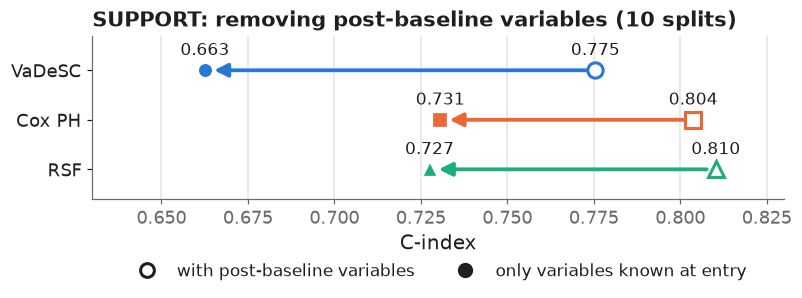

In [13]:
leak = pd.read_csv(R10 / "support10_leakage.csv")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
names = ["VaDeSC", "Cox PH", "RSF"]
y = np.arange(len(names))[::-1]
for yi, k in zip(y, names):
    w, wo = per_split(leak, f"{k}, with").mean(), per_split(leak, f"{k}, without").mean()
    ax.annotate("", xy=(wo, yi), xytext=(w, yi),
                arrowprops=dict(arrowstyle="-|>", color=COLORS[k], lw=2.5, mutation_scale=18, shrinkA=6, shrinkB=6))
    ax.plot(w, yi, MARKERS[k], color="white", markeredgecolor=COLORS[k], markeredgewidth=2, markersize=10)
    ax.plot(wo, yi, MARKERS[k], color=COLORS[k], markeredgecolor="white", markeredgewidth=1.5, markersize=10)
    ax.annotate(f"{w:.3f}", (w, yi), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=11)
    ax.annotate(f"{wo:.3f}", (wo, yi), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=11)
ax.set_yticks(y, names); ax.grid(False, axis="y"); ax.set_ylim(-0.6, len(names) - 0.3)
ax.set(xlabel="C-index", xlim=(0.63, 0.83))
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="white", markeredgecolor=INK, markeredgewidth=2, label="with post-baseline variables"),
                   Line2D([], [], marker="o", ls="", color=INK, label="only variables known at entry")],
          loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=11)
ax.set_title("SUPPORT: removing post-baseline variables (10 splits)", loc="left", fontweight="bold")
plt.tight_layout(); save(fig, "leakage_10splits")

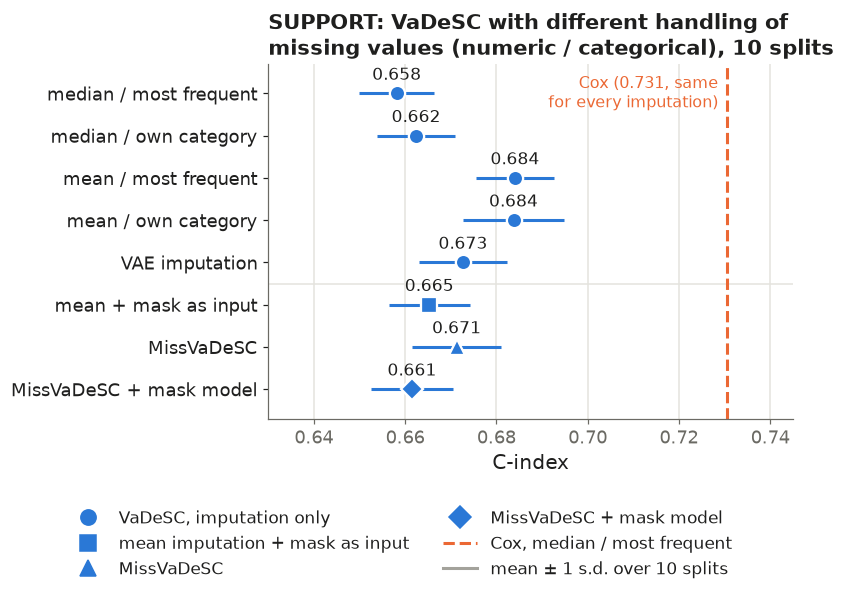

In [14]:
# VaDeSC with different ways of handling missing values on SUPPORT; Cox as a reference line
VAR = [("VaDeSC, median/mode", "median / most frequent", "o"),
       ("VaDeSC, median/missing category", "median / own category", "o"),
       ("VaDeSC, mean/mode", "mean / most frequent", "o"),
       ("VaDeSC, mean/missing category", "mean / own category", "o"),
       ("VaDeSC, VAE imputation", "VAE imputation", "o"),
       ("VaDeSC + mask input", "mean + mask as input", "s"),
       ("MissVaDeSC", "MissVaDeSC", "^"),
       ("MissVaDeSC + mask model", "MissVaDeSC + mask model", "D")]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ps = [per_split(sup_miss, v) for v, _, _ in VAR]
dots(ax, [lab for _, lab, _ in VAR], [p.mean() for p in ps], [p.std() for p in ps],
     [COLORS["VaDeSC"]] * len(VAR), [m for _, _, m in VAR])
ax.axhline(2.5, color=GRID, lw=1)  # imputation above, mask variants below
cox = per_split(sup_miss, "Cox PH, median/mode").mean()
ax.axvline(cox, color=COLORS["Cox PH"], ls="--", lw=2)
ax.annotate(f"Cox ({cox:.3f}, same\nfor every imputation)", (cox, len(VAR) - 1), xytext=(-6, 0), textcoords="offset points",
            ha="right", va="center", fontsize=10.5, color=COLORS["Cox PH"])
ax.set(xlabel="C-index", xlim=(0.63, 0.745))
ax.set_title("SUPPORT: VaDeSC with different handling of\nmissing values (numeric / categorical), 10 splits", loc="left", fontweight="bold")
plt.tight_layout()
h = [Line2D([], [], marker="o", ls="", color=COLORS["VaDeSC"], markersize=10, label="VaDeSC, imputation only"),
     Line2D([], [], marker="s", ls="", color=COLORS["VaDeSC"], markersize=10, label="mean imputation + mask as input"),
     Line2D([], [], marker="^", ls="", color=COLORS["VaDeSC"], markersize=10, label="MissVaDeSC"),
     Line2D([], [], marker="D", ls="", color=COLORS["VaDeSC"], markersize=10, label="MissVaDeSC + mask model"),
     Line2D([], [], color=COLORS["Cox PH"], ls="--", lw=2, label="Cox, median / most frequent"),
     Line2D([], [], color=GRAY, lw=2, label="mean ± 1 s.d. over 10 splits")]
fig.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=11)
save(fig, "support_missing_10splits")

In [15]:
print("saved:", sorted(p.name for p in OUT.glob("*.png")))

saved: ['datasets_km.png', 'imputation.png', 'leakage.png', 'leakage_10splits.png', 'missingness_mechanisms.png', 'missingness_support.png', 'missingness_survival.png', 'real_prediction.png', 'real_prediction_10splits.png', 'sim_benchmark.png', 'support_clusters.png', 'support_latent.png', 'support_missing_10splits.png', 'support_missingness.png']
